# Alerta temprana de abandono estudiantil

**Demostración con datos inventados.** Ningún dato corresponde a personas ni instituciones reales: la base se genera con `generar_datos.py`.

**Problema.** Una institución con 4 sedes pierde estudiantes durante el primer semestre y se entera tarde, cuando ya dejaron de asistir. Las coordinaciones necesitan saber cada semana a quién llamar primero.

**Solución.** Un modelo de machine learning estima el riesgo de abandono de cada estudiante con lo que ya se registra en las primeras 8 semanas (asistencia, notas, asignaturas reprobadas, pagos, uso de la plataforma y tutorías). El resultado es una lista semanal en Excel, una hoja por sede, ordenada por riesgo y con el motivo principal de cada alerta.

**Contenido**
1. Exploración de los datos
2. Comparación de modelos: regresión logística, KNN y Random Forest
3. Elección del umbral de alerta
4. Lista semanal "A quién llamar" por sede

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             precision_recall_curve, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 2026
VIOLETA, GRIS, ROJO = "#2d1b8f", "#9aa0ad", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
Path("images").mkdir(exist_ok=True)
Path("salidas").mkdir(exist_ok=True)

def marca_demo(fig):
    fig.text(0.99, 0.01, "Ejemplo · datos inventados", ha="right", va="bottom", fontsize=8, color=GRIS)

## 1. Exploración de los datos

In [2]:
df = pd.read_csv("datos/estudiantes_inventados.csv")
print(f"{len(df):,} estudiantes · tasa de abandono {df.abandono.mean():.1%}")
df.head()

1,500 estudiantes · tasa de abandono 24.1%


,id_estudiante,sede,carrera,jornada,edad,primera_generacion,trabaja,gratuidad,asistencia_pct,promedio_notas,asignaturas_reprobadas,cuotas_atrasadas,ingresos_plataforma_semana,tutorias_asistidas,abandono
0,EST-10366,Sede Norte,Administración,Vespertina,36,0,1,1,48.0,4.0,1,0,9,0,1
1,EST-10212,Sede Centro,Contabilidad,Diurna,36,1,0,1,79.9,5.6,0,0,5,1,0
2,EST-10854,Sede Centro,Electricidad,Vespertina,27,1,1,1,94.7,4.0,0,0,5,0,0
3,EST-10919,Sede Centro,Mecánica Automotriz,Diurna,28,0,1,1,90.4,5.5,0,0,8,0,0
4,EST-11312,Sede Centro,Mecánica Automotriz,Diurna,21,0,1,1,78.9,6.6,0,0,6,1,0


In [3]:
df.groupby("sede").agg(estudiantes=("id_estudiante", "count"), abandono=("abandono", "mean")).style.format({"abandono": "{:.1%}"})

,estudiantes,abandono
sede,,
Sede Centro,522,21.6%
Sede Costa,240,28.3%
Sede Norte,419,26.7%
Sede Sur,319,21.6%


La asistencia y las asignaturas reprobadas separan con claridad a quienes abandonan de quienes siguen:

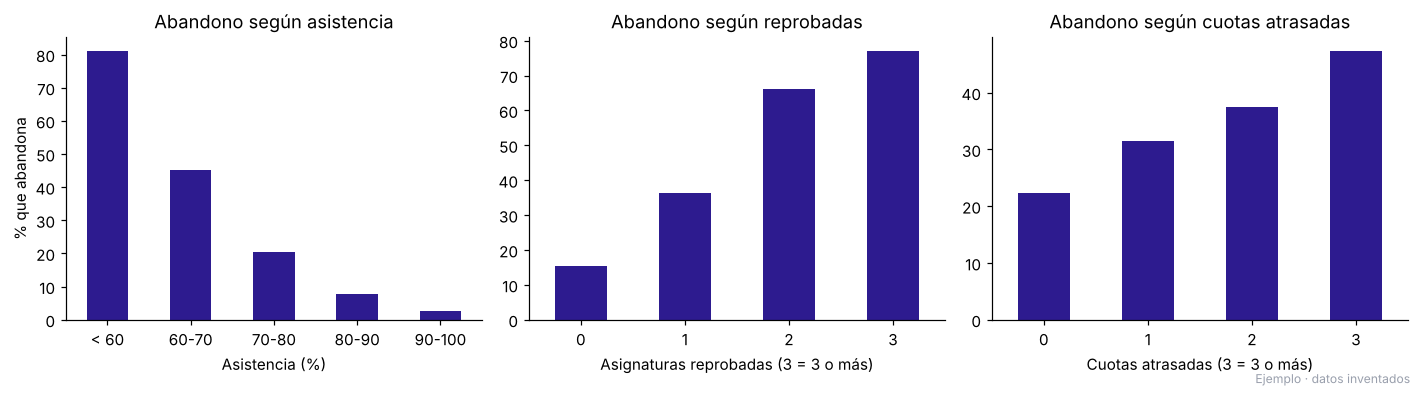

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
tramos = pd.cut(df.asistencia_pct, [0, 60, 70, 80, 90, 100], labels=["< 60", "60-70", "70-80", "80-90", "90-100"])
df.groupby(tramos, observed=True).abandono.mean().mul(100).plot.bar(ax=ejes[0], color=VIOLETA)
ejes[0].set(title="Abandono según asistencia", xlabel="Asistencia (%)", ylabel="% que abandona")
df.groupby(df.asignaturas_reprobadas.clip(upper=3)).abandono.mean().mul(100).plot.bar(ax=ejes[1], color=VIOLETA)
ejes[1].set(title="Abandono según reprobadas", xlabel="Asignaturas reprobadas (3 = 3 o más)", ylabel="")
df.groupby(df.cuotas_atrasadas.clip(upper=3)).abandono.mean().mul(100).plot.bar(ax=ejes[2], color=VIOLETA)
ejes[2].set(title="Abandono según cuotas atrasadas", xlabel="Cuotas atrasadas (3 = 3 o más)", ylabel="")
for ax in ejes: ax.tick_params(axis="x", rotation=0)
marca_demo(fig); fig.tight_layout(); fig.savefig("images/exploracion.png", bbox_inches="tight"); plt.show()

## 2. Comparación de modelos

Se comparan tres modelos con validación cruzada estratificada y ajuste de hiperparámetros (GridSearchCV). La métrica principal es el **recall**: en una alerta temprana es peor no detectar a un estudiante que se va a ir que llamar a uno que se iba a quedar. También se mira el área bajo la curva precisión-recall (AP), que no se infla con el desbalance de clases.

In [5]:
numericas = ["edad", "asistencia_pct", "promedio_notas", "asignaturas_reprobadas", "cuotas_atrasadas",
             "ingresos_plataforma_semana", "tutorias_asistidas", "primera_generacion", "trabaja", "gratuidad"]
categoricas = ["sede", "jornada", "carrera"]
X, y = df[numericas + categoricas], df.abandono
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)

prepro = ColumnTransformer([("num", StandardScaler(), numericas),
                            ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
candidatos = {
    "Regresión logística": (LogisticRegression(max_iter=2000), {"modelo__C": [0.01, 0.1, 1, 10]}),
    "KNN": (KNeighborsClassifier(), {"modelo__n_neighbors": [5, 15, 25, 41], "modelo__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(random_state=SEMILLA),
                      {"modelo__n_estimators": [300], "modelo__max_depth": [4, 6, 10], "modelo__min_samples_leaf": [5, 20]}),
}
ajustados, filas = {}, []
for nombre, (modelo, grilla) in candidatos.items():
    busqueda = GridSearchCV(Pipeline([("prepro", prepro), ("modelo", modelo)]), grilla, cv=cv, scoring="average_precision")
    busqueda.fit(X_train, y_train)
    ajustados[nombre] = busqueda.best_estimator_
    p = busqueda.predict_proba(X_test)[:, 1]
    filas.append({"Modelo": nombre, "AP": average_precision_score(y_test, p), "ROC AUC": roc_auc_score(y_test, p),
                  "Recall llamando al 20%": recall_score(y_test, p >= np.quantile(p, 0.80)), "Mejores parámetros": busqueda.best_params_})
comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion.style.format({"AP": "{:.3f}", "ROC AUC": "{:.3f}", "Recall llamando al 20%": "{:.1%}"})

,AP,ROC AUC,Recall llamando al 20%,Mejores parámetros
Modelo,,,,
Regresión logística,0.865,0.929,70.3%,{'modelo__C': 0.01}
KNN,0.846,0.908,67.0%,"{'modelo__n_neighbors': 41, 'modelo__weights': 'distance'}"
Random Forest,0.854,0.926,67.0%,"{'modelo__max_depth': 10, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}"


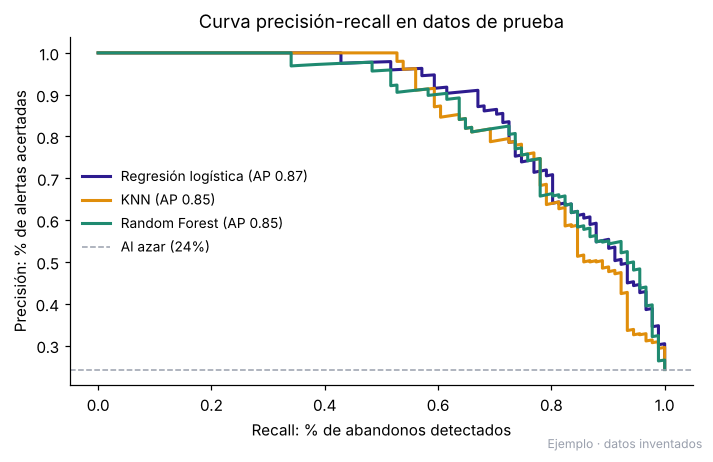

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
colores = {"Regresión logística": VIOLETA, "KNN": "#e08e0b", "Random Forest": "#1f8a70"}
for nombre, modelo in ajustados.items():
    prec, rec, _ = precision_recall_curve(y_test, modelo.predict_proba(X_test)[:, 1])
    ax.plot(rec, prec, label=f"{nombre} (AP {comparacion.loc[nombre, 'AP']:.2f})", color=colores[nombre], lw=2)
ax.axhline(y_test.mean(), ls="--", color=GRIS, lw=1, label=f"Al azar ({y_test.mean():.0%})")
ax.set(xlabel="Recall: % de abandonos detectados", ylabel="Precisión: % de alertas acertadas", title="Curva precisión-recall en datos de prueba")
ax.legend(frameon=False, fontsize=9)
marca_demo(fig); fig.tight_layout(); fig.savefig("images/comparacion_modelos.png", bbox_inches="tight"); plt.show()

**Lectura.** Se elige el modelo con mayor AP. KNN queda por debajo: con muchas variables y una relación casi lineal entre ellas y el riesgo, comparar vecinos aporta menos que ponderar cada variable. Un modelo simple que se puede explicar es una ventaja real: la coordinación necesita entender por qué alguien aparece en la lista.

## 3. Umbral de alerta

El umbral no lo decide el modelo sino la capacidad de llamar. Si cada sede puede contactar cada semana al **20%** de sus estudiantes, la pregunta es qué parte de los abandonos queda dentro de ese 20%.

Modelo elegido: Regresión logística
Llamando al 20% de mayor riesgo se detecta el 70% de los abandonos.
El 85% de las llamadas son a estudiantes que efectivamente iban a abandonar (llamando al azar sería el 24%).
              precision    recall  f1-score   support

       Sigue       0.91      0.96      0.93       284
    Abandona       0.85      0.70      0.77        91

    accuracy                           0.90       375
   macro avg       0.88      0.83      0.85       375
weighted avg       0.90      0.90      0.90       375



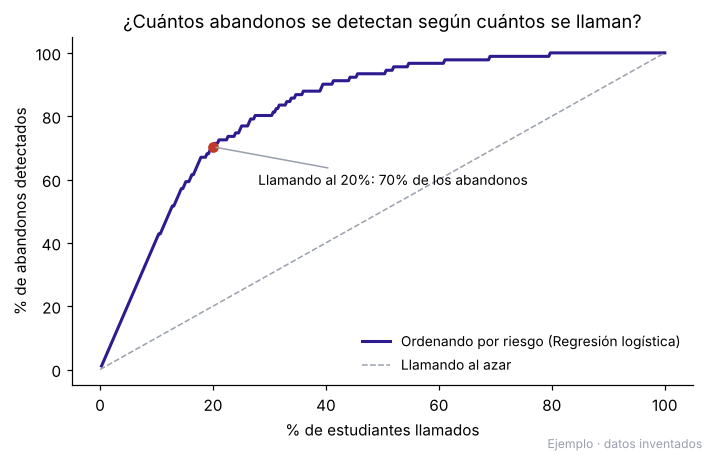

In [7]:
mejor = comparacion.AP.idxmax()
modelo = ajustados[mejor]
p_test = modelo.predict_proba(X_test)[:, 1]
CAPACIDAD = 0.20
umbral = float(np.quantile(p_test, 1 - CAPACIDAD))
alertas = p_test >= umbral
print(f"Modelo elegido: {mejor}")
print(f"Llamando al {alertas.mean():.0%} de mayor riesgo se detecta el {recall_score(y_test, alertas):.0%} de los abandonos.")
print(f"El {y_test[alertas].mean():.0%} de las llamadas son a estudiantes que efectivamente iban a abandonar "
      f"(llamando al azar sería el {y_test.mean():.0%}).")
print(classification_report(y_test, alertas, target_names=["Sigue", "Abandona"]))

curva = pd.DataFrame({"riesgo": p_test, "abandono": y_test.values}).sort_values("riesgo", ascending=False)
curva["pct_llamados"] = np.arange(1, len(curva) + 1) / len(curva)
curva["pct_detectados"] = curva.abandono.cumsum() / curva.abandono.sum()
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(curva.pct_llamados * 100, curva.pct_detectados * 100, color=VIOLETA, lw=2, label=f"Ordenando por riesgo ({mejor})")
ax.plot([0, 100], [0, 100], ls="--", color=GRIS, lw=1, label="Llamando al azar")
d = recall_score(y_test, alertas) * 100
ax.scatter([CAPACIDAD * 100], [d], color=ROJO, zorder=3)
ax.annotate(f"Llamando al 20%: {d:.0f}% de los abandonos", (CAPACIDAD * 100, d), xytext=(28, d - 12), fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set(xlabel="% de estudiantes llamados", ylabel="% de abandonos detectados", title="¿Cuántos abandonos se detectan según cuántos se llaman?")
ax.legend(frameon=False, fontsize=9, loc="lower right")
marca_demo(fig); fig.tight_layout(); fig.savefig("images/curva_deteccion.png", bbox_inches="tight"); plt.show()

## 4. Lista semanal "A quién llamar"

El modelo se vuelve a entrenar con todos los datos y se aplica a los estudiantes vigentes. Para cada alerta se indica el **motivo principal**: la variable que más sube su riesgo respecto de un estudiante promedio.

In [8]:
modelo.fit(X, y)
vigentes = df.copy()  # en un caso real: solo estudiantes con matrícula vigente esta semana
vigentes["riesgo"] = modelo.predict_proba(X)[:, 1]

motivos = {
    "asistencia_pct": "Baja asistencia", "promedio_notas": "Promedio bajo", "asignaturas_reprobadas": "Asignaturas reprobadas",
    "cuotas_atrasadas": "Cuotas atrasadas", "ingresos_plataforma_semana": "Poco uso de la plataforma",
    "tutorias_asistidas": "Sin tutorías", "trabaja": "Trabaja", "primera_generacion": "Primera generación",
}
def motivo_principal(fila):
    base = X.median(numeric_only=True)
    aportes = {}
    for var in motivos:
        prueba = X.loc[[fila.name]].copy()
        prueba[var] = base[var]
        aportes[var] = vigentes.at[fila.name, "riesgo"] - modelo.predict_proba(prueba)[0, 1]
    return motivos[max(aportes, key=aportes.get)]

lista = vigentes[vigentes.riesgo >= umbral].copy()
lista["motivo_principal"] = lista.apply(motivo_principal, axis=1)
lista["prioridad"] = pd.cut(lista.riesgo, [0, 0.5, 0.75, 1.0], labels=["Media", "Alta", "Muy alta"], include_lowest=True)
columnas = ["id_estudiante", "carrera", "jornada", "riesgo", "prioridad", "motivo_principal",
            "asistencia_pct", "promedio_notas", "asignaturas_reprobadas", "cuotas_atrasadas"]
lista = lista.sort_values("riesgo", ascending=False)[["sede"] + columnas]
print(f"{len(lista)} estudiantes en alerta de {len(vigentes)}")
lista.groupby("sede").size().rename("en alerta").to_frame()

351 estudiantes en alerta de 1500


,en alerta
sede,
Sede Centro,110
Sede Costa,62
Sede Norte,109
Sede Sur,70


In [9]:
ruta = "salidas/a_quien_llamar.xlsx"
with pd.ExcelWriter(ruta, engine="openpyxl") as xl:
    resumen = lista.groupby(["sede", "prioridad"], observed=False).size().unstack(fill_value=0)
    resumen.to_excel(xl, sheet_name="Resumen")
    for sede, grupo in lista.groupby("sede"):
        grupo[columnas].assign(riesgo=grupo.riesgo.round(2)).to_excel(xl, sheet_name=sede, index=False)
print("Guardado:", ruta)
lista.head(10)

Guardado: salidas/a_quien_llamar.xlsx


,sede,id_estudiante,carrera,jornada,riesgo,prioridad,motivo_principal,asistencia_pct,promedio_notas,asignaturas_reprobadas,cuotas_atrasadas
659,Sede Costa,EST-10112,Administración,Diurna,0.986815,Muy alta,Baja asistencia,38.8,2.3,4,0
768,Sede Norte,EST-10655,Educación Parvularia,Vespertina,0.962391,Muy alta,Baja asistencia,40.5,3.7,3,0
918,Sede Centro,EST-10452,Administración,Diurna,0.960613,Muy alta,Baja asistencia,34.6,2.9,2,0
687,Sede Centro,EST-10053,Administración,Diurna,0.960525,Muy alta,Baja asistencia,23.3,4.1,1,0
242,Sede Costa,EST-10784,Turismo,Diurna,0.951702,Muy alta,Baja asistencia,39.9,1.8,0,1
647,Sede Centro,EST-11225,Enfermería (TENS),Vespertina,0.950875,Muy alta,Baja asistencia,34.6,2.6,1,0
383,Sede Norte,EST-11116,Informática,Diurna,0.941366,Muy alta,Baja asistencia,40.4,2.4,2,0
1176,Sede Sur,EST-10497,Mecánica Automotriz,Diurna,0.937360,Muy alta,Asignaturas reprobadas,63.1,3.5,6,0
339,Sede Costa,EST-11398,Informática,Diurna,0.932002,Muy alta,Baja asistencia,38.0,2.8,1,0
489,Sede Norte,EST-11180,Administración,Diurna,0.929630,Muy alta,Promedio bajo,53.3,2.0,2,0


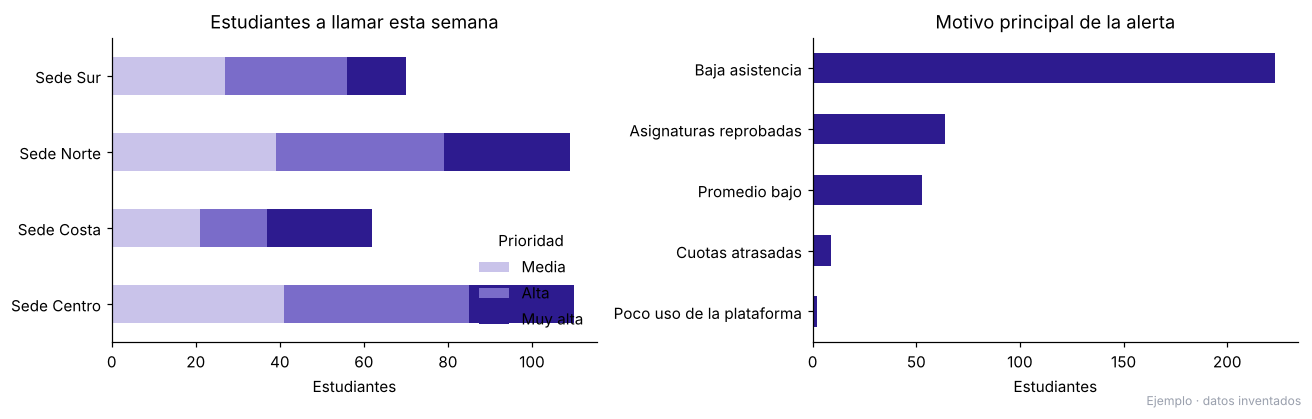

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
lista.groupby(["sede", "prioridad"], observed=False).size().unstack().plot.barh(
    stacked=True, ax=ejes[0], color=["#c9c3ea", "#7a6cc9", VIOLETA])
ejes[0].set(title="Estudiantes a llamar esta semana", xlabel="Estudiantes", ylabel="")
ejes[0].legend(title="Prioridad", frameon=False, loc="lower right")
lista.motivo_principal.value_counts().sort_values().plot.barh(ax=ejes[1], color=VIOLETA)
ejes[1].set(title="Motivo principal de la alerta", xlabel="Estudiantes", ylabel="")
marca_demo(fig); fig.tight_layout(); fig.savefig("images/lista_semanal.png", bbox_inches="tight"); plt.show()

## Conclusiones

- Con datos que la institución ya registra se puede ordenar a todos los estudiantes por riesgo desde la semana 8, antes de que dejen de asistir.
- El umbral se fija según cuántas llamadas puede hacer cada sede: la curva de detección muestra cuántos abandonos se cubren con cada nivel de esfuerzo.
- La lista sale en Excel, una hoja por sede, con el motivo de cada alerta para que la conversación con el estudiante sea concreta.
- Siguientes pasos en un caso real: actualizar la lista cada semana de forma automática, registrar el resultado de cada llamada y medir si las tutorías bajan el abandono.

---
¿Necesitas algo así con los datos de tu institución? [Sivax Intelligence](https://sivax-intelligent.netlify.app/) · sivax.contacto@gmail.com